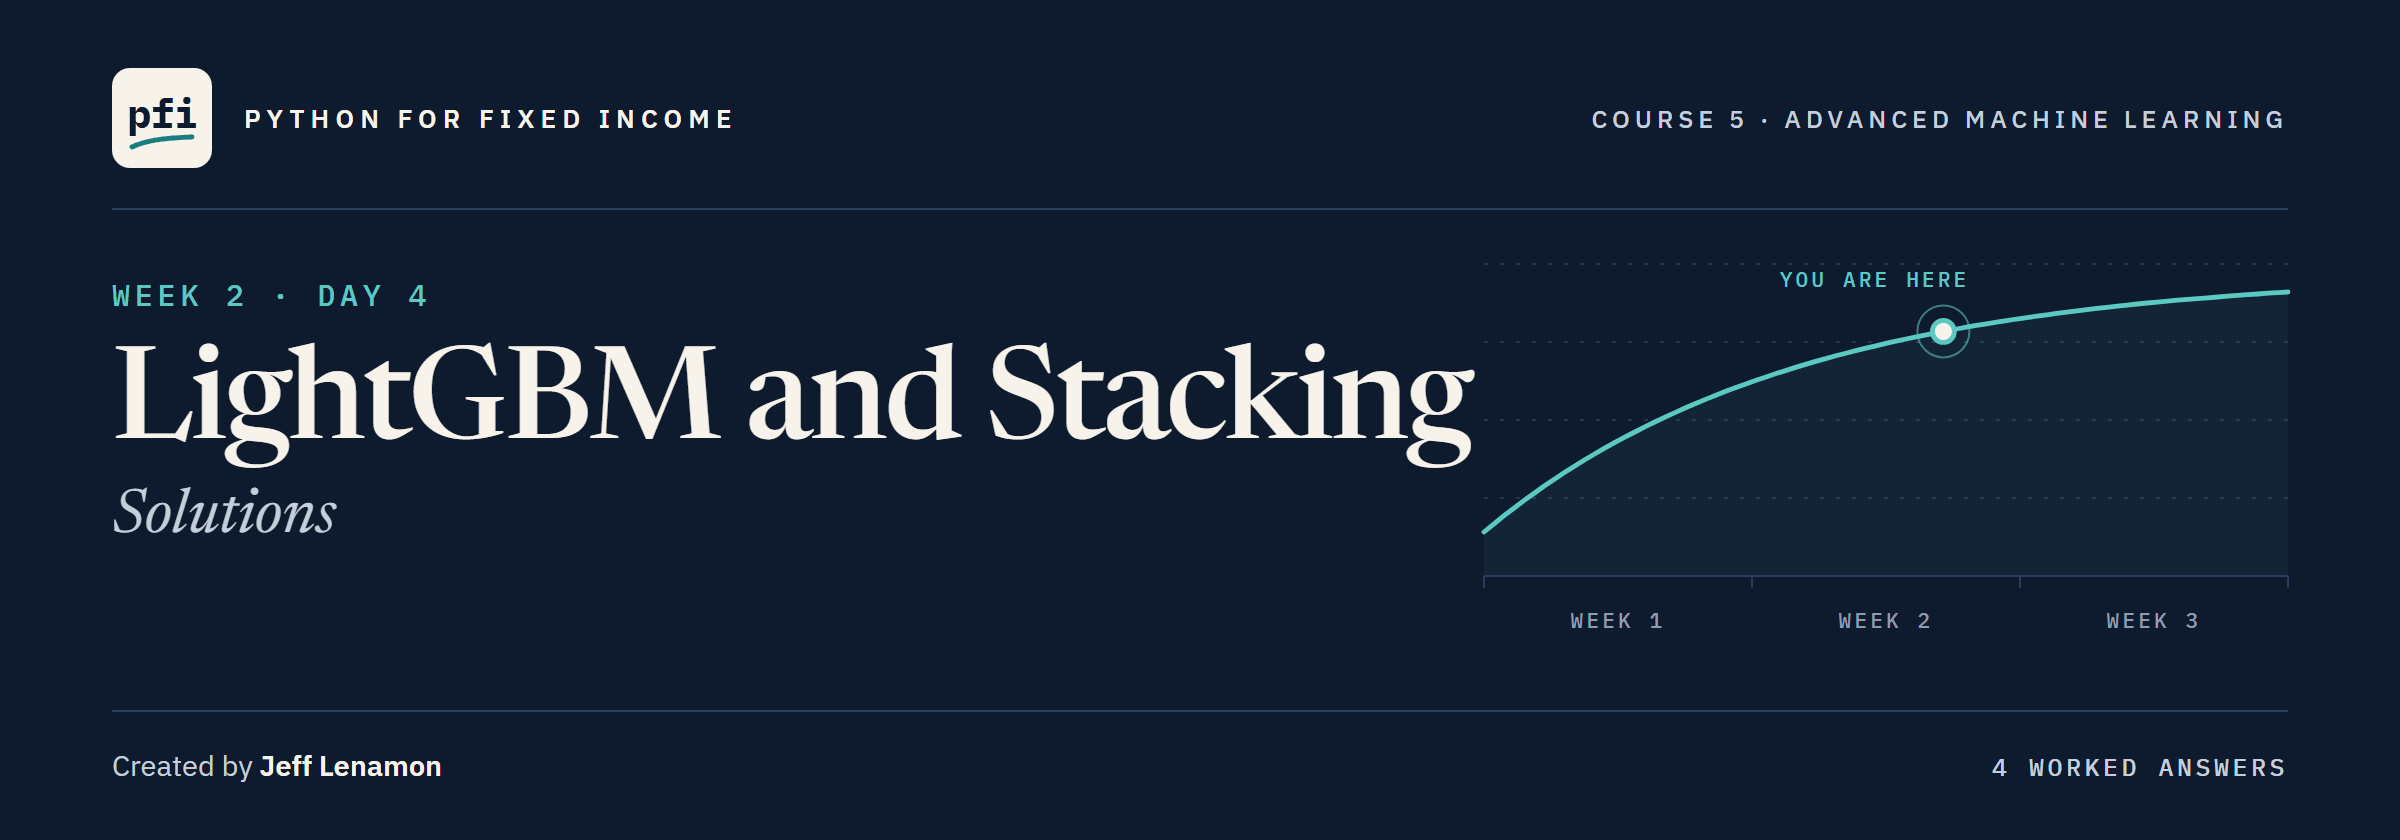

# LightGBM and Stacking: Solutions

Week 2, Day 4. The full notebook with every exercise worked. Try each one yourself first.

**Data:** `credit_card_default.csv`, 30,000 card accounts in Taiwan in 2005: **real**, UCI Machine Learning Repository dataset 350, CC BY 4.0. Citation: Yeh, I. (2009). Default of Credit Card Clients [Dataset]. UCI Machine Learning Repository. https://doi.org/10.24432/C55S3H.

> This course is educational content created in a personal capacity. Nothing here is investment advice or a recommendation to buy or sell any security. All portfolio data is synthetic.

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day4/09_lightgbm_and_stacking_solutions.ipynb)

# Problem Statement

## Business Context

Day 8 gave the desk XGBoost; LightGBM is another widely used boosting library, the same boosting with trees grown another way.
Day 3's forest, Day 8's braked XGBoost and LightGBM now score within a few thousandths of each other on Course 4's card accounts.
A reviewer asks whether one model built on top of them ranks the accounts better than any of them, and how to build it without fooling ourselves.
The accounts are real, from Taiwan in 2005, so they describe consumer credit there and then, not US credit today.
The four person columns are never features, because a model that used them would sort people by them.

## Objectives

Fit LightGBM and score it on training and validation rows, read its trees from a table of nodes and draw one, and count the split points its bins allow.
Measure three of its settings on five folds, stop its trees on rows carved from the training rows, and read its two built-in importances.
Build out-of-fold columns, fit a stacking layer on them, check `StackingClassifier` against the hand version, and compare a stack with its members and with plain averages.

## Data Dictionary

`credit_card_default.csv`, one row per account:

1. `LIMIT_BAL`: credit limit, NT dollars
2. `PAY_0`, `PAY_2` to `PAY_6`: repayment status, September back to April 2005, where -1 is paid on time, 1 to 9 is months late, and -2 and 0 are undocumented (used as numbers, a modelling choice, as in Course 4)
3. `BILL_AMT1` to `BILL_AMT6`: the bill, NT dollars, September back to April
4. `PAY_AMT1` to `PAY_AMT6`: the amount paid, NT dollars, September back to April
5. `default payment next month`: 1 if the account defaulted the following month, **the target**
6. `ID`, `SEX`, `EDUCATION`, `MARRIAGE`, `AGE`: never used

# Setting Up

## Course Setup

Run this cell and move on: it fixes the seed and finds the course data.

In [1]:
# today's setup: the thread settings, the seed, and where the course data lives
import os
from pathlib import Path

# one thread for the maths libraries, so every run prints the same last digits (this must run before numpy is imported)
os.environ["OMP_NUM_THREADS"] = "1"
os.environ["OPENBLAS_NUM_THREADS"] = "1"

# the seed: one number for every random choice, so every run makes the same choices
SEED = 42

# the course data: the repo's data folder on your machine, GitHub in Colab
DATA = "../../../data/"
if not Path(DATA + "benchmark.csv").exists():
    DATA = "https://raw.githubusercontent.com/lenamonj/python-fixed-income/main/data/"

## Importing the Libraries

In [2]:
# to load and work with the data
import numpy as np
import pandas as pd

# to draw charts, and a slider
import matplotlib.pyplot as plt
import seaborn as sns
from ipywidgets import interact

# to split the accounts, fold the training rows, and collect out-of-fold outputs
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate, cross_val_predict

# the course's earlier models, and stacking
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier, StackingClassifier
from xgboost import XGBClassifier

# today's library
import lightgbm as lgb
from lightgbm import LGBMClassifier

# to score a model's outputs and its flags
from sklearn.metrics import roc_auc_score, average_precision_score, accuracy_score, recall_score, precision_score, f1_score

# one look for every chart, and four decimals in every table
sns.set_theme(style="whitegrid")
sns.set_palette("colorblind")
plt.rcParams["figure.figsize"] = (10, 5)
pd.set_option("display.float_format", "{:.4f}".format)

# Loading the Data

## Reading the Card File

In [3]:
# the 30,000 accounts; the target's name has spaces, so we keep it in a variable
card = pd.read_csv(DATA + "credit_card_default.csv")
TARGET = "default payment next month"

# every column except the ID, the four person columns and the target
X = card.drop(columns=["ID", "SEX", "EDUCATION", "MARRIAGE", "AGE", TARGET])
y = card[TARGET]
FEATURES = list(X.columns)
print(len(FEATURES), "features")

19 features


## Checking the Shape and the Default Share

In [4]:
# rows and columns, and how many accounts defaulted
print(card.shape)
print("Defaults:", y.sum(), " Share:", round(y.mean() * 100, 2), "percent")

(30000, 25)
Defaults: 6636  Share: 22.12 percent


**The file Course 4 used, unchanged, so we rebuild its rows exactly.**

# Data Preparation for Modeling

## Course 4's Split

In [5]:
# Course 4's split: a fifth of the accounts to test, then a quarter of the rest to validation, defaults spread evenly
X_rest, X_test, y_rest, y_test = train_test_split(X, y, test_size=0.2, stratify=y, random_state=SEED)
X_train, X_valid, y_train, y_valid = train_test_split(X_rest, y_rest, test_size=0.25, stratify=y_rest, random_state=SEED)
print("Training:", len(X_train), " Validation:", len(X_valid), " Test:", len(X_test))
print("Default share:", round(y_train.mean(), 4), round(y_valid.mean(), 4), round(y_test.mean(), 4))

# five folds of the training rows, shuffled with the seed: every fold score and every out-of-fold column today
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

Training: 18000  Validation: 6000  Test: 6000
Default share: 0.2212 0.2212 0.2212


The same accounts as Course 4 and the days before, each set with the same default share.

Models are reported on the validation rows; Course 5 chooses nothing on them and never scores the test rows.

**Training rows fit and choose, validation rows report, test rows stay closed.**

# Model Building

## LightGBM in One Line

**LightGBM** is Day 7's boosting on the log-odds of default, as Day 8's XGBoost runs it: every account starts at the training default rate, and each tree, fitted to what the trees before it still miss, adds a step.
Its trees are grown another way, and the next section shows how.
As with XGBoost, `n_jobs=1` keeps every run's numbers the same; `verbose=-1` keeps LightGBM's training log off the page.

In [6]:
# LightGBM with its own defaults, on one thread, with the seed, its log switched off
lgbm = LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1).fit(X_train, y_train)

## The Settings It Chose

In [7]:
# the settings we left alone
params = lgbm.get_params()
print({name: params[name] for name in ["n_estimators", "learning_rate", "num_leaves", "max_depth", "min_child_samples", "reg_lambda"]})

{'n_estimators': 100, 'learning_rate': 0.1, 'num_leaves': 31, 'max_depth': -1, 'min_child_samples': 20, 'reg_lambda': 0.0}


Where XGBoost showed `None`, LightGBM shows every default as a number: 100 trees at a step of 0.1.

`num_leaves`, 31, caps the leaves of each tree; `max_depth` -1 means no limit on how many questions deep it goes.

`min_child_samples`, 20, is the fewest training accounts a leaf may hold; `reg_lambda` is Day 8's leaf penalty, off by default.

## Scoring on Training and Validation Rows

`model_performance_classification` is Course 4's Day 8's, with ROC AUC first, repeated as one cell.

In [8]:
# flag at or above the threshold, then the ROC AUC and four measures of the flags in one row
def model_performance_classification(model, predictors, target, threshold=0.5):
    flags = (model.predict_proba(predictors)[:, 1] >= threshold).astype(int)
    return pd.DataFrame({
        "ROC AUC": [roc_auc_score(target, model.predict_proba(predictors)[:, 1])],
        "Accuracy": [accuracy_score(target, flags)],
        "Recall": [recall_score(target, flags, zero_division=0)],
        "Precision": [precision_score(target, flags, zero_division=0)],
        "F1": [f1_score(target, flags, zero_division=0)],
    })

In [9]:
# the defaults on the accounts they were fitted on, and on the validation accounts, at 0.5
train_valid = pd.concat([model_performance_classification(lgbm, X_train, y_train).T,
                         model_performance_classification(lgbm, X_valid, y_valid).T], axis=1)
train_valid.columns = ["training", "validation"]
train_valid

,training,validation
ROC AUC,0.8979,0.7726
Accuracy,0.8466,0.8207
Recall,0.4350,0.3572
Precision,0.7718,0.6801
F1,0.5564,0.4684


### Interpretation of the Scores

ROC AUC is 0.8979 on the training rows and 0.7726 on the validation rows, a gap of 0.125.

Day 8's XGBoost defaults scored 0.9550 and 0.7592, a gap of 0.196.

**Out of the box LightGBM ranks unseen accounts better than XGBoost's defaults and memorises less. Its trees are built another way.**

# How LightGBM Grows a Tree

## Leaf by Leaf

Day 8's XGBoost trees grow **level by level**: every leaf at one depth is split before any below it, and a cap on depth stops them, so 32 leaves fill five full levels of questions.
LightGBM grows **leaf by leaf**: at each step it splits the one leaf, anywhere in the tree, whose split has the largest gain (Day 8's), and it stops at `num_leaves` leaves.

**Predict 1**

Q. The first tree stops at 31 leaves. How many questions down is its deepest leaf? Write down a number.

## The First Tree as a Table

`.booster_` hands back the LightGBM model inside, and its `.trees_to_dataframe()` lists every node of every tree, one row each, as Day 8's XGBoost table did.
`0-S3` is tree 0's fourth split, numbered in the order the splits were made, and `0-L5` one of its leaves; `node_depth` is 1 at the root, and `count` holds the training accounts that reach the node.

In [10]:
# every node of the 100 trees, then the first tree with its nodes as row labels
trees = lgbm.booster_.trees_to_dataframe()
first = trees[trees["tree_index"] == 0].set_index("node_index")
first.loc[["0-S0", "0-S1"], ["node_depth", "split_feature", "threshold", "count", "left_child", "right_child"]]

,node_depth,split_feature,threshold,count,left_child,right_child
node_index,,,,,,
0-S0,1,PAY_0,1.5000,18000,0-S1,0-S5
0-S1,2,PAY_2,1.5000,16115,0-S2,0-S7


In [11]:
# the first tree's leaves: how many, the deepest in questions, and the accounts they hold
leaves = first[first["split_feature"].isna()]
print("Leaves:", len(leaves), " Deepest leaf:", leaves["node_depth"].max() - 1, "questions down")
print("Accounts in a leaf: fewest", leaves["count"].min(), " most", leaves["count"].max())

Leaves: 31  Deepest leaf: 8 questions down
Accounts in a leaf: fewest 20  most 4782


The root asks `PAY_0 <= 1.5` and sends 16,115 accounts left and 1,885 right, the cut Day 8's XGBoost made at `PAY_0 < 2.0`.

Split 1 opens the left side and split 5 the right: the right waited four splits for its turn.

The deepest leaf sits 8 questions down, where a level-by-level tree of 31 leaves stops at 5; leaves hold 20 to 4,782 accounts.

## Drawing the Tree Grow

An **icicle chart** draws a tree as rows of bars: the root across the top, every node under its parent, as wide as the accounts that reach it.
First each node's place along the row, then the order each split was made.

In [12]:
# each node's left edge: a left child starts where its parent starts, a right child after the left child's accounts
first["left_edge"] = 0
for node in first.sort_values("node_depth").index:
    left, right = first.loc[node, "left_child"], first.loc[node, "right_child"]
    if isinstance(left, str):
        first.loc[left, "left_edge"] = first.loc[node, "left_edge"]
        first.loc[right, "left_edge"] = first.loc[node, "left_edge"] + first.loc[left, "count"]

# the order each split was made (the number after S; a leaf gets 99), and the order of the split above each node
first["order"] = [int(name.split("S")[1]) if "-S" in name else 99 for name in first.index]
first["parent_order"] = [first.loc[parent, "order"] if isinstance(parent, str) else -1 for parent in first["parent_index"]]

In [13]:
# the tree after its first k splits: splits coloured by the order they were made, leaves pale, five questions dashed
def icicle(k, ax):
    shown = first[first["parent_order"] < k]
    for node in shown.index:
        row, split = shown.loc[node], shown.loc[node, "order"] < k
        ax.barh(row["node_depth"] - 1, row["count"], left=row["left_edge"], height=0.92, edgecolor="white",
                color=plt.cm.viridis(row["order"] / 30) if split else "gainsboro")
        if split and row["count"] > 600:
            ax.text(row["left_edge"] + row["count"] / 2, row["node_depth"] - 1, row["order"], ha="center", va="center",
                    color="white" if row["order"] < 18 else "black")
    ax.axhline(5.5, color="C3", linestyle="--", label="the last row of a level-by-level tree of 32 leaves")
    ax.set(xlim=(0, len(X_train)), ylim=(8.6, -0.6), yticks=range(9), xlabel="Training accounts reaching the node",
           ylabel="Questions above the node")
    ax.set_title(f"{k} splits made, {(shown['order'] >= k).sum()} leaves")
    ax.legend(loc="lower right")

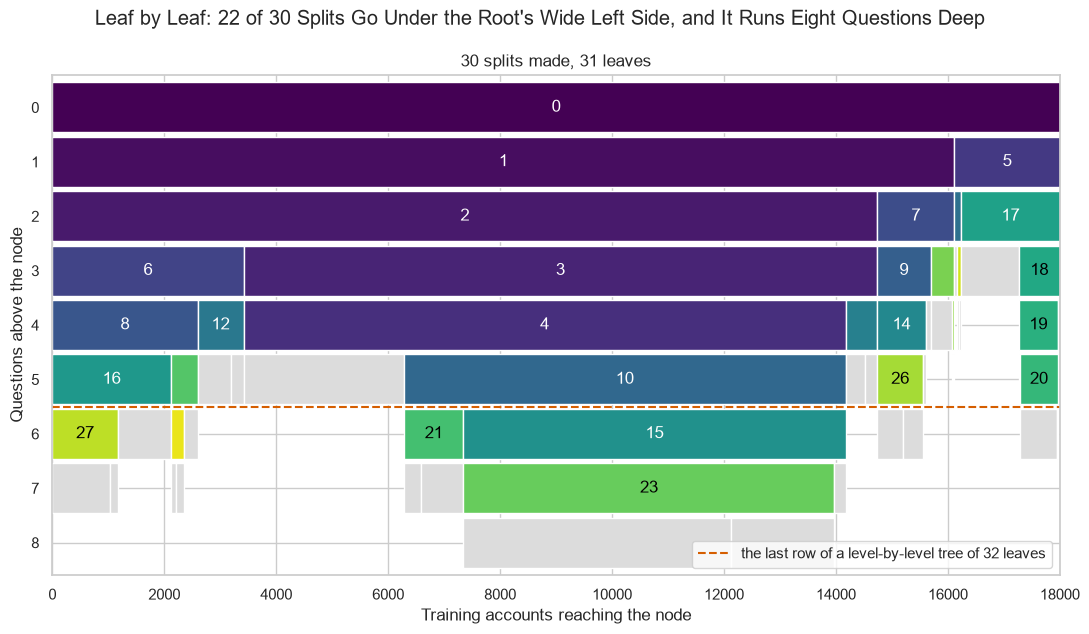

In [14]:
# the whole first tree: 30 splits, 31 leaves
fig, ax = plt.subplots(figsize=(13, 6.5))
icicle(30, ax)
fig.suptitle("Leaf by Leaf: 22 of 30 Splits Go Under the Root's Wide Left Side, and It Runs Eight Questions Deep")
plt.show()

Each bar's width is its accounts; the numbers are the order the splits were made, dark first.

The left side, 16,115 accounts, holds 22 of the 30 splits and reaches 8 questions; the right side, 1,885 accounts, holds 7 and reaches 6.

A level-by-level tree would have spent its 31 leaves evenly above the dashed line.

### Your Turn: Grow It Split by Split

Slide k and watch where each new split lands: always on the leaf with the most to gain.

In [15]:
# your turn: slide the number of splits made and watch the first tree grow
def grow(k=10):
    fig, ax = plt.subplots(figsize=(13, 6.5))
    icicle(k, ax)
    plt.show()

interact(grow, k=(1, 30));

interactive(children=(IntSlider(value=10, description='k', max=30, min=1), Output()), _dom_classes=('widget-in…

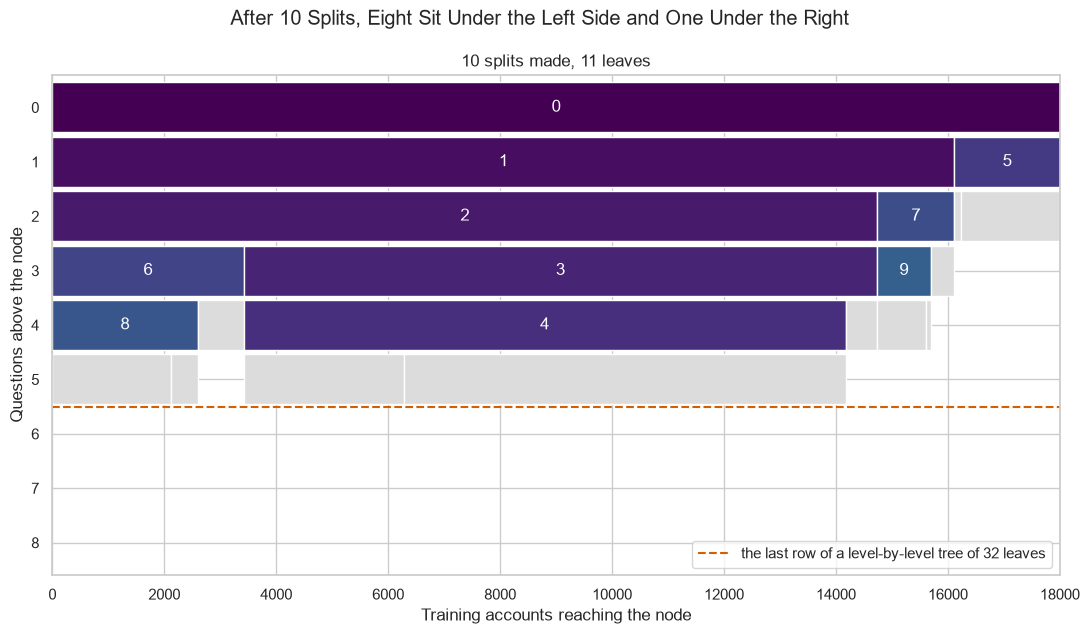

In [16]:
# the slider's starting position, drawn as a still picture (sliders do not run on GitHub)
fig, ax = plt.subplots(figsize=(13, 6.5))
icicle(10, ax)
fig.suptitle("After 10 Splits, Eight Sit Under the Left Side and One Under the Right")
plt.show()

After 10 splits the deepest leaf on the left is already 5 questions down; the right side has asked only one question of its own.

## Every Tree's Deepest Leaf

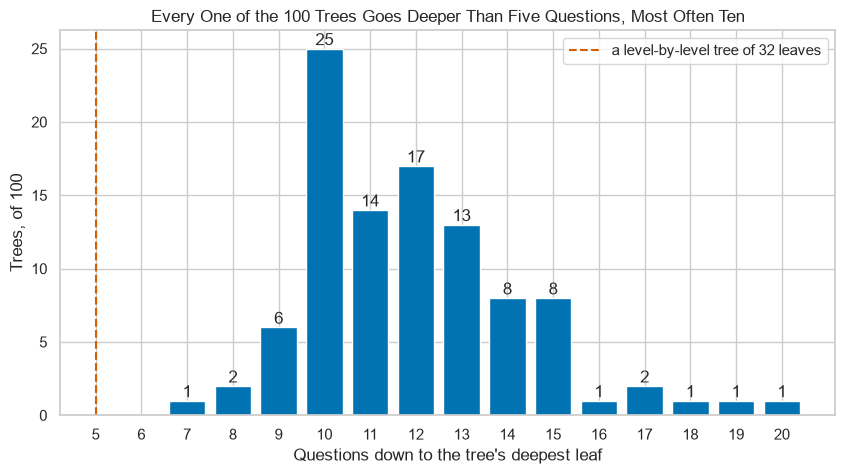

In [17]:
# the deepest leaf of each of the 100 trees, in questions
deepest = trees[trees["split_feature"].isna()].groupby("tree_index")["node_depth"].max() - 1
deepest_counts = deepest.value_counts().sort_index()

# trees by their deepest leaf, the level-by-level depth of 5 dashed
bars = plt.bar(deepest_counts.index, deepest_counts.values)
plt.bar_label(bars, fmt="%.0f")
plt.axvline(5, color="C3", linestyle="--", label="a level-by-level tree of 32 leaves")
plt.xticks(range(5, 21))
plt.xlabel("Questions down to the tree's deepest leaf")
plt.ylabel("Trees, of 100")
plt.title("Every One of the 100 Trees Goes Deeper Than Five Questions, Most Often Ten")
plt.legend()
plt.show()

The 100 trees reach 7 to 20 questions deep, most often 10.

`num_leaves` caps the size; with `max_depth` at -1 nothing caps the depth.

## Bins, Not Every Value

Before growing any tree, LightGBM sorts each column's values into a limited number of **bins**, and a split can only fall between two bins.
Day 4 counted 14,404 distinct values of `BILL_AMT1` on the training rows.

**Predict 2**

Q. How many different thresholds do the 100 trees use on `BILL_AMT1`? Write down a number.

In [18]:
# for each column: distinct values on the training rows, and the distinct thresholds the 100 trees split it at
bins = pd.DataFrame({"distinct values": X_train.nunique(), "thresholds used": trees.groupby("split_feature")["threshold"].nunique()})
bins.loc[["BILL_AMT1", "PAY_AMT1", "LIMIT_BAL", "PAY_0"]]

,distinct values,thresholds used
BILL_AMT1,14404,142
PAY_AMT1,5717,121
LIMIT_BAL,78,47
PAY_0,11,7


`max_bin`, 255 by default, caps the bins of a column, so a column offers at most 254 thresholds.

In [19]:
# thresholds a tree could try: every gap between two distinct values, against at most 254 a column once binned
# (np.minimum keeps the smaller of the two numbers, column by column)
print("Without bins:", (X_train.nunique() - 1).sum(), " With bins:", np.minimum(X_train.nunique() - 1, 254).sum())

Without bins: 114804  With bins: 3183


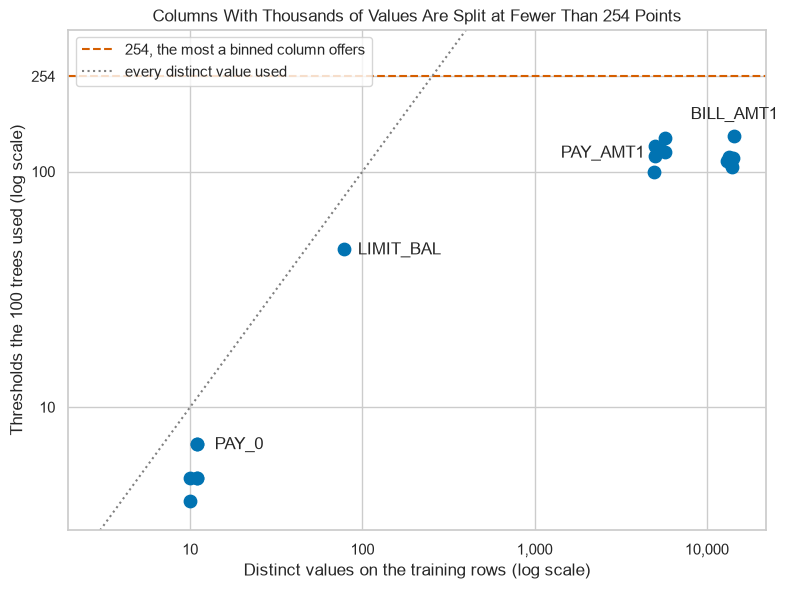

In [20]:
# distinct values against thresholds used, one dot per column, both on log axes, the bin ceiling and the diagonal dashed
plt.figure(figsize=(9, 6.5))
plt.scatter(bins["distinct values"], bins["thresholds used"], s=80)
for name, offset in [("BILL_AMT1", (0, 12)), ("PAY_AMT1", (-45, -4)), ("LIMIT_BAL", (40, -4)), ("PAY_0", (30, -4))]:
    plt.annotate(name, (bins.loc[name, "distinct values"], bins.loc[name, "thresholds used"]), textcoords="offset points",
                 xytext=offset, ha="center")
plt.axhline(254, color="C3", linestyle="--", label="254, the most a binned column offers")
plt.plot([3, 400], [3, 400], color="gray", linestyle=":", label="every distinct value used")
plt.xscale("log")
plt.yscale("log")
plt.xticks([10, 100, 1000, 10000], ["10", "100", "1,000", "10,000"])
plt.yticks([10, 100, 254], ["10", "100", "254"])
plt.ylim(3, 400)
plt.xlabel("Distinct values on the training rows (log scale)")
plt.ylabel("Thresholds the 100 trees used (log scale)")
plt.title("Columns With Thousands of Values Are Split at Fewer Than 254 Points")
plt.legend(loc="upper left")
plt.show()

The bills and payments, thousands of values each, are cut at about 100 to 150 thresholds, `BILL_AMT1` at 142; the status columns at a handful each.

A tree here weighs 3,183 thresholds at most instead of 114,804.

**Leaf-wise trees go deep where the accounts are, and bins cut the split search 36-fold. Next we measure which settings matter on these accounts.**

# Three Settings by Five Folds

## Leaves, Leaf Size and Step

Each setting is scored on the five folds with `cross_validate(..., return_train_score=True)` (Day 5's), one setting changed at a time from the defaults.

**Predict 3**

The defaults' 31 leaves score 0.7749 on the held-out folds.

Q. Sketch ROC AUC on the fitted folds and on the held-out folds as `num_leaves` goes 4, 8, 16, 31, 63, 127 and 255.

In [21]:
# three settings at several values, every other setting at LightGBM's default: ROC AUC on the fitted and held-out folds
settings = {"num_leaves": [4, 8, 16, 31, 63, 127, 255], "min_child_samples": [5, 20, 50, 100, 200, 400, 800],
            "learning_rate": [0.01, 0.03, 0.1, 0.3, 1.0]}
board = []
for setting, values in settings.items():
    for value in values:
        result = cross_validate(LGBMClassifier(random_state=SEED, n_jobs=1, verbose=-1, **{setting: value}), X_train, y_train,
                                cv=folds, scoring="roc_auc", return_train_score=True, n_jobs=1)
        board.append([setting, value, result["train_score"].mean(), result["test_score"].mean(), result["test_score"].std()])
board = pd.DataFrame(board, columns=["setting", "value", "fitted folds", "held-out folds", "fold sd"])

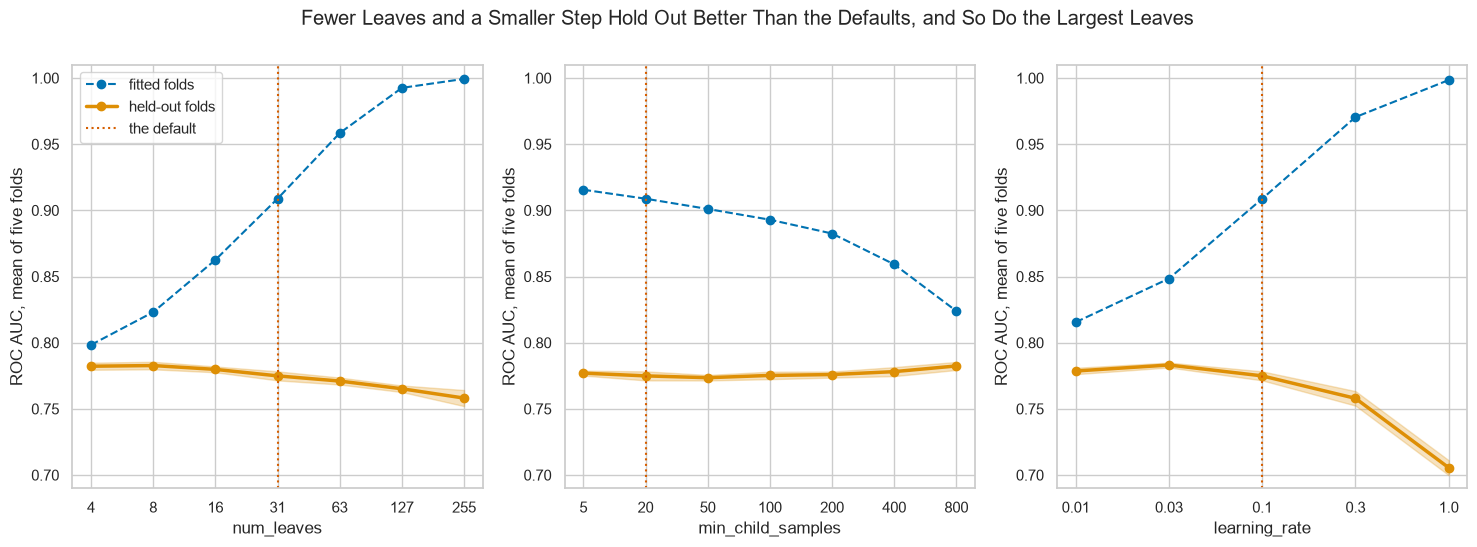

In [22]:
# one panel per setting: fitted folds dashed, held-out folds solid with one fold standard deviation shaded, the default dotted
fig, axes = plt.subplots(1, 3, figsize=(18, 5.5))
for ax, (setting, values) in zip(axes, settings.items()):
    one = board[board["setting"] == setting]
    ax.plot(range(len(values)), one["fitted folds"], marker="o", linestyle="--", label="fitted folds")
    ax.plot(range(len(values)), one["held-out folds"], marker="o", linewidth=2.5, label="held-out folds")
    ax.fill_between(range(len(values)), one["held-out folds"] - one["fold sd"], one["held-out folds"] + one["fold sd"], color="C1", alpha=0.25)
    ax.axvline(values.index(params[setting]), color="C3", linestyle=":", label="the default")
    ax.set(xticks=range(len(values)), xticklabels=values, xlabel=setting, ylim=(0.69, 1.01), ylabel="ROC AUC, mean of five folds")
axes[0].legend(loc="upper left")
fig.suptitle("Fewer Leaves and a Smaller Step Hold Out Better Than the Defaults, and So Do the Largest Leaves")
plt.show()

In [23]:
# each setting's best held-out score, the spread across folds, then the num_leaves rows in full
print(board.loc[board.groupby("setting")["held-out folds"].idxmax(), ["setting", "value", "held-out folds"]].to_string(index=False))
print("Fold standard deviation:", round(board["fold sd"].min(), 4), "to", round(board["fold sd"].max(), 4))
board[board["setting"] == "num_leaves"]

          setting    value  held-out folds
    learning_rate   0.0300          0.7831
min_child_samples 800.0000          0.7824
       num_leaves   8.0000          0.7827
Fold standard deviation: 0.0018 to 0.0061


,setting,value,fitted folds,held-out folds,fold sd
0,num_leaves,4.0000,0.7984,0.7822,0.0027
1,num_leaves,8.0000,0.8231,0.7827,0.0029
2,num_leaves,16.0000,0.8626,0.7798,0.0022
3,num_leaves,31.0000,0.9088,0.7749,0.0034
4,num_leaves,63.0000,0.9584,0.7710,0.0026
5,num_leaves,127.0000,0.9925,0.7652,0.0025
6,num_leaves,255.0000,0.9993,0.7582,0.0061


### Interpretation of the Settings

`num_leaves` 8 holds out best, 0.7827; past 31 the held-out score falls to 0.7582 at 255 while the fitted folds climb to 0.9993.

`min_child_samples` 800 holds out at 0.7824, and a step of 0.03 at 0.7831.

The fold standard deviation is as large as several of these gaps.

These are light choices on training rows; Day 11 tunes several settings at once, honestly.

**A smaller step needs more trees: let the stopping rows count them.**

# Early Stopping on the Stopping Rows

## Carving the Stopping Rows

Day 8's carve, unchanged: a fifth of the training rows held back to stop on, so the validation rows only report.

In [24]:
# a fifth of the training rows held back to stop on, defaults spread evenly; the rest fit the trees
X_fit, X_stop, y_fit, y_stop = train_test_split(X_train, y_train, test_size=0.2, stratify=y_train, random_state=SEED)
print("Fit rows:", len(X_fit), " Stopping rows:", len(X_stop))

Fit rows: 14400  Stopping rows: 3600


## LightGBM's Spelling

LightGBM takes the rows to score as `eval_X` and `eval_y`, named by `eval_names`; it never stops on the fit rows themselves, so here the stopping rows decide.
It stops through a **callback**, a function the library calls after every tree: `lgb.early_stopping(50, verbose=False)` is Day 8's patience of 50, quietly.
LightGBM 4.7 replaces its old `eval_set`, the name XGBoost keeps, and the old name prints a warning.
`.best_iteration_` is the trees kept, `.evals_result_` holds each pair's log loss by round, and `predict_proba` then uses the trees kept.

In [25]:
# up to 1,000 trees at three steps, each stopped on the stopping rows
stopped = {}
for rate in [0.1, 0.05, 0.02]:
    model = LGBMClassifier(n_estimators=1000, learning_rate=rate, random_state=SEED, n_jobs=1, verbose=-1)
    model.fit(X_fit, y_fit, eval_X=(X_fit, X_stop), eval_y=(y_fit, y_stop), eval_names=["fit", "stop"],
              callbacks=[lgb.early_stopping(50, verbose=False)])
    stopped[rate] = model

In [26]:
# one row per step: trees kept, rounds run, the lowest stopping log loss, and ROC AUC on the fit rows and once on the validation rows
pd.DataFrame([[m.best_iteration_, len(m.evals_result_["stop"]["binary_logloss"]), min(m.evals_result_["stop"]["binary_logloss"]),
               roc_auc_score(y_fit, m.predict_proba(X_fit)[:, 1]), roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1])]
              for m in stopped.values()],
             index=list(stopped),
             columns=["trees kept", "rounds run", "lowest stopping log loss", "fit-row ROC AUC", "validation ROC AUC"])

,trees kept,rounds run,lowest stopping log loss,fit-row ROC AUC,validation ROC AUC
0.1000,25,75,0.4358,0.8400,0.7765
0.0500,53,103,0.4341,0.8430,0.7797
0.0200,172,222,0.4341,0.8530,0.7788


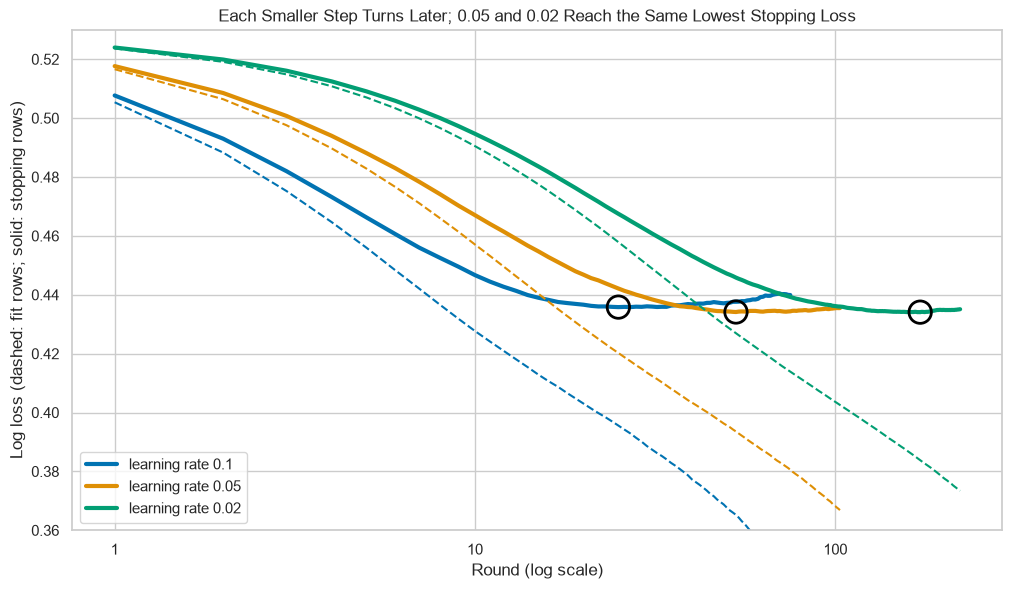

In [27]:
# each step: fit-row (dashed) and stopping-row (solid) log loss by round, the round kept ringed
fig, ax = plt.subplots(figsize=(12, 6.5))
for (rate, model), colour in zip(stopped.items(), ["C0", "C1", "C2"]):
    history = model.evals_result_
    rounds = np.arange(1, len(history["stop"]["binary_logloss"]) + 1)
    ax.plot(rounds, history["fit"]["binary_logloss"], color=colour, linewidth=1.5, linestyle="--")
    ax.plot(rounds, history["stop"]["binary_logloss"], color=colour, linewidth=3, label=f"learning rate {rate}")
    best = model.best_iteration_
    ax.scatter(best, history["stop"]["binary_logloss"][best - 1], s=260, facecolor="none", edgecolor="black", linewidth=2, zorder=3)
ax.set(xscale="log", xticks=[1, 10, 100], xticklabels=["1", "10", "100"], ylim=(0.36, 0.53), xlabel="Round (log scale)",
       ylabel="Log loss (dashed: fit rows; solid: stopping rows)")
ax.set_title("Each Smaller Step Turns Later; 0.05 and 0.02 Reach the Same Lowest Stopping Loss")
ax.legend(loc="lower left")
plt.show()

A step of 0.1 keeps 25 trees, 0.05 keeps 53, and 0.02 keeps 172.

0.05 and 0.02 reach the same lowest stopping log loss, 0.4341; 0.05 scores 0.7797 on the validation rows, 0.02 scores 0.7788.

**At 0.05 the stopping rows keep 53 trees: 53 trees at 0.05 is today's LightGBM from here on.**

# What LightGBM Leans On

## Two Built-In Importances

`feature_importances_` follows the model's `importance_type`, whose default `"split"` counts each column's splits, as Day 4 counted a forest's.
`.booster_.feature_importance("gain")` sums each column's split gain instead.

In [28]:
# the defaults' splits on each column and each column's share of the total gain, ranked both ways
importance = pd.DataFrame({"splits": lgbm.feature_importances_, "gain": lgbm.booster_.feature_importance("gain")}, index=FEATURES)
importance["gain percent"] = importance["gain"] / importance["gain"].sum() * 100
importance["split rank"] = importance["splits"].rank(ascending=False).astype(int)
importance["gain rank"] = importance["gain"].rank(ascending=False).astype(int)
importance.loc[["BILL_AMT1", "LIMIT_BAL", "PAY_AMT2", "PAY_0"]]

,splits,gain,gain percent,split rank,gain rank
BILL_AMT1,278,2018.7449,5.7473,1,3
LIMIT_BAL,244,1972.4251,5.6154,3,4
PAY_AMT2,259,2163.6349,6.1598,2,2
PAY_0,114,14182.1086,40.3758,14,1


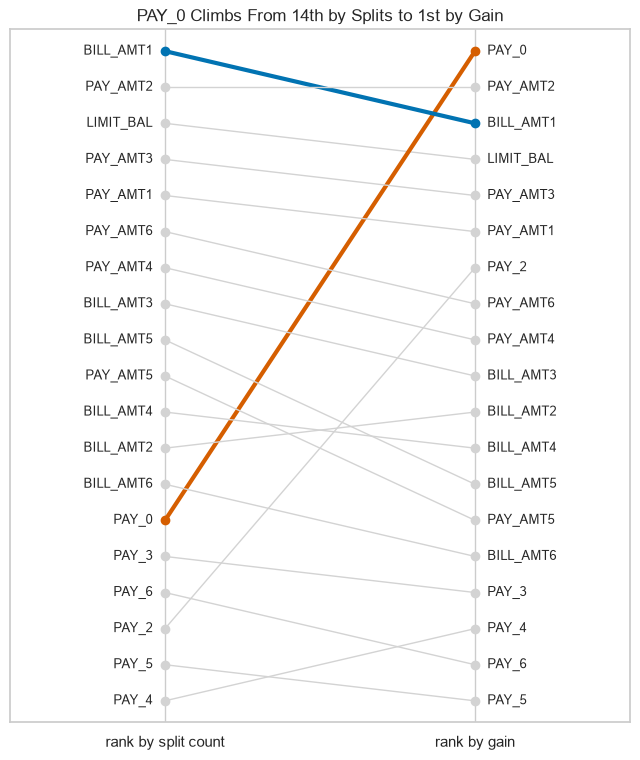

In [29]:
# a slope chart: each column's rank by split count on the left, by gain on the right, two columns highlighted
fig, ax = plt.subplots(figsize=(8, 9))
for name in FEATURES:
    colour = {"PAY_0": "C3", "BILL_AMT1": "C0"}.get(name, "lightgray")
    ax.plot([0, 1], importance.loc[name, ["split rank", "gain rank"]], marker="o", color=colour, linewidth=3 if colour != "lightgray" else 1)
    ax.text(-0.04, importance.loc[name, "split rank"], name, ha="right", va="center", fontsize=9)
    ax.text(1.04, importance.loc[name, "gain rank"], name, ha="left", va="center", fontsize=9)
ax.set(xticks=[0, 1], xticklabels=["rank by split count", "rank by gain"], xlim=(-0.5, 1.5), ylim=(19.6, 0.4), yticks=[])
ax.set_title("PAY_0 Climbs From 14th by Splits to 1st by Gain")
plt.show()

`BILL_AMT1` has the most splits; `PAY_0` ranks 14th by splits and first by gain, with 40.4 percent of it.

Split counts favour columns with many values, as Day 4's planted column showed; gain weighs what each split bought.

Either way this is what the model leans on: an association in this file.

**Name `importance_type` whenever you quote LightGBM's importance.**

# Model Performance Comparison

## The Booster Built Into `scikit-learn`

`HistGradientBoostingClassifier` is the classifier twin of Day 7's `HistGradientBoostingRegressor`: it bins each column and grows 31-leaf trees leaf by leaf, as LightGBM does.
With more than 10,000 rows it stops itself, on a tenth of the rows it is given; `.n_iter_` is the trees it kept.

In [30]:
# scikit-learn's own binned booster at its defaults
hist = HistGradientBoostingClassifier(random_state=SEED).fit(X_train, y_train)
print("Trees:", hist.n_iter_, " Validation ROC AUC:", round(roc_auc_score(y_valid, hist.predict_proba(X_valid)[:, 1]), 4))

Trees: 55  Validation ROC AUC: 0.7773


## Six Models, One Validation Set

Course 4's logistic regression, Day 3's chosen forest and Day 8's braked XGBoost join today's LightGBM.
Each is refitted on all 18,000 training rows with the settings and tree count its own day chose; Day 8 fitted its 394 trees on the 14,400 fit rows.

In [31]:
# the course's best models with their own day's settings, and today's LightGBM, refitted on all the training rows
models = {"logistic": Pipeline([("scale", StandardScaler()), ("logit", LogisticRegression(max_iter=1000))]),
          "forest": RandomForestClassifier(n_estimators=200, max_features=8, min_samples_leaf=100, random_state=SEED, n_jobs=1),
          "xgboost": XGBClassifier(n_estimators=394, learning_rate=0.05, reg_lambda=1000, random_state=SEED, n_jobs=1),
          "lightgbm": LGBMClassifier(n_estimators=53, learning_rate=0.05, random_state=SEED, n_jobs=1, verbose=-1)}
for model in models.values():
    model.fit(X_train, y_train)

In [32]:
# ROC AUC on the training and validation rows: the four, LightGBM's defaults and scikit-learn's booster
six = {"Logistic regression (Course 4)": models["logistic"], "Chosen forest (Day 3)": models["forest"],
       "Braked XGBoost (Day 8)": models["xgboost"], "LightGBM, 53 trees at 0.05": models["lightgbm"],
       "LightGBM defaults": lgbm, "HistGradientBoosting defaults": hist}
comparison = pd.DataFrame({"training": [roc_auc_score(y_train, m.predict_proba(X_train)[:, 1]) for m in six.values()],
                           "validation": [roc_auc_score(y_valid, m.predict_proba(X_valid)[:, 1]) for m in six.values()]},
                          index=list(six)).sort_values("validation")
comparison

,training,validation
Logistic regression (Course 4),0.7296,0.7190
LightGBM defaults,0.8979,0.7726
HistGradientBoosting defaults,0.8592,0.7773
"LightGBM, 53 trees at 0.05",0.8355,0.7799
Braked XGBoost (Day 8),0.8100,0.7827
Chosen forest (Day 3),0.8204,0.7844


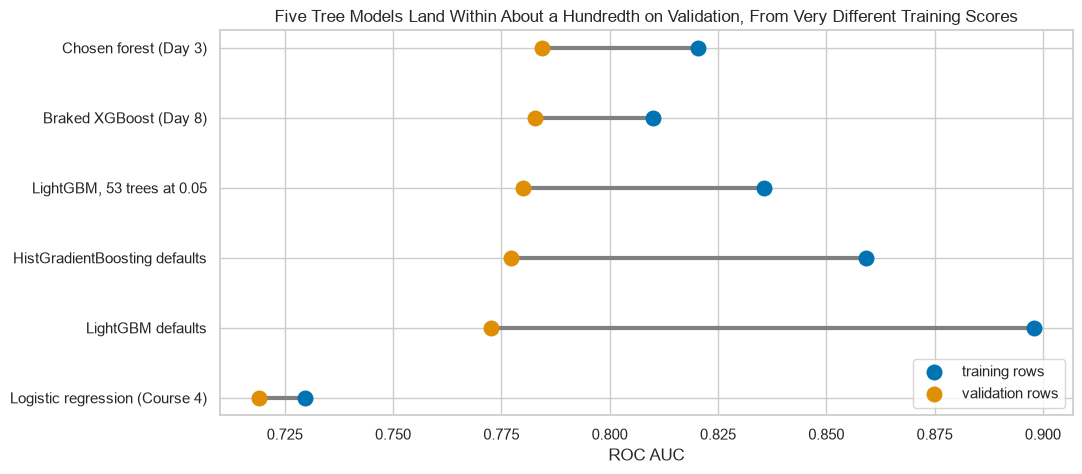

In [33]:
# the dumbbell: training against validation ROC AUC for each model, highest validation at the top
fig, ax = plt.subplots(figsize=(11, 5))
ax.hlines(comparison.index, comparison["validation"], comparison["training"], color="gray", linewidth=3)
ax.scatter(comparison["training"], comparison.index, s=110, label="training rows", zorder=3)
ax.scatter(comparison["validation"], comparison.index, s=110, label="validation rows", zorder=3)
ax.set_xlabel("ROC AUC")
ax.set_title("Five Tree Models Land Within About a Hundredth on Validation, From Very Different Training Scores")
ax.legend(loc="lower right")
plt.show()

Day 3's chosen forest leads at 0.7844; the braked XGBoost refitted on all the training rows scores 0.7827, today's LightGBM 0.7799.

The forest and the braked XGBoost barely memorise; LightGBM's defaults fall furthest, from 0.8979.

**Five tree models land within 0.0118 on validation, each by a different route. Next we ask whether a model built on top of them beats the best.**

# Stacking From Out-of-Fold Outputs

## The Idea

![Stacking in four steps. One: the 18,000 training rows go to four members, logistic regression, Day 3's forest, Day 8's XGBoost and today's LightGBM, each run through five folds. Two: four out-of-fold columns, one per member, each output from 0 to 1 from a fit that never saw the account, beside the outcome, 0 or 1; a dashed box says never use outputs on the rows each member was fitted on. Three: a logistic regression, the layer, fitted on the four columns. Four: a validation account goes through the four members refitted on all 18,000 rows, giving four outputs, and the layer turns them into the stack's output.](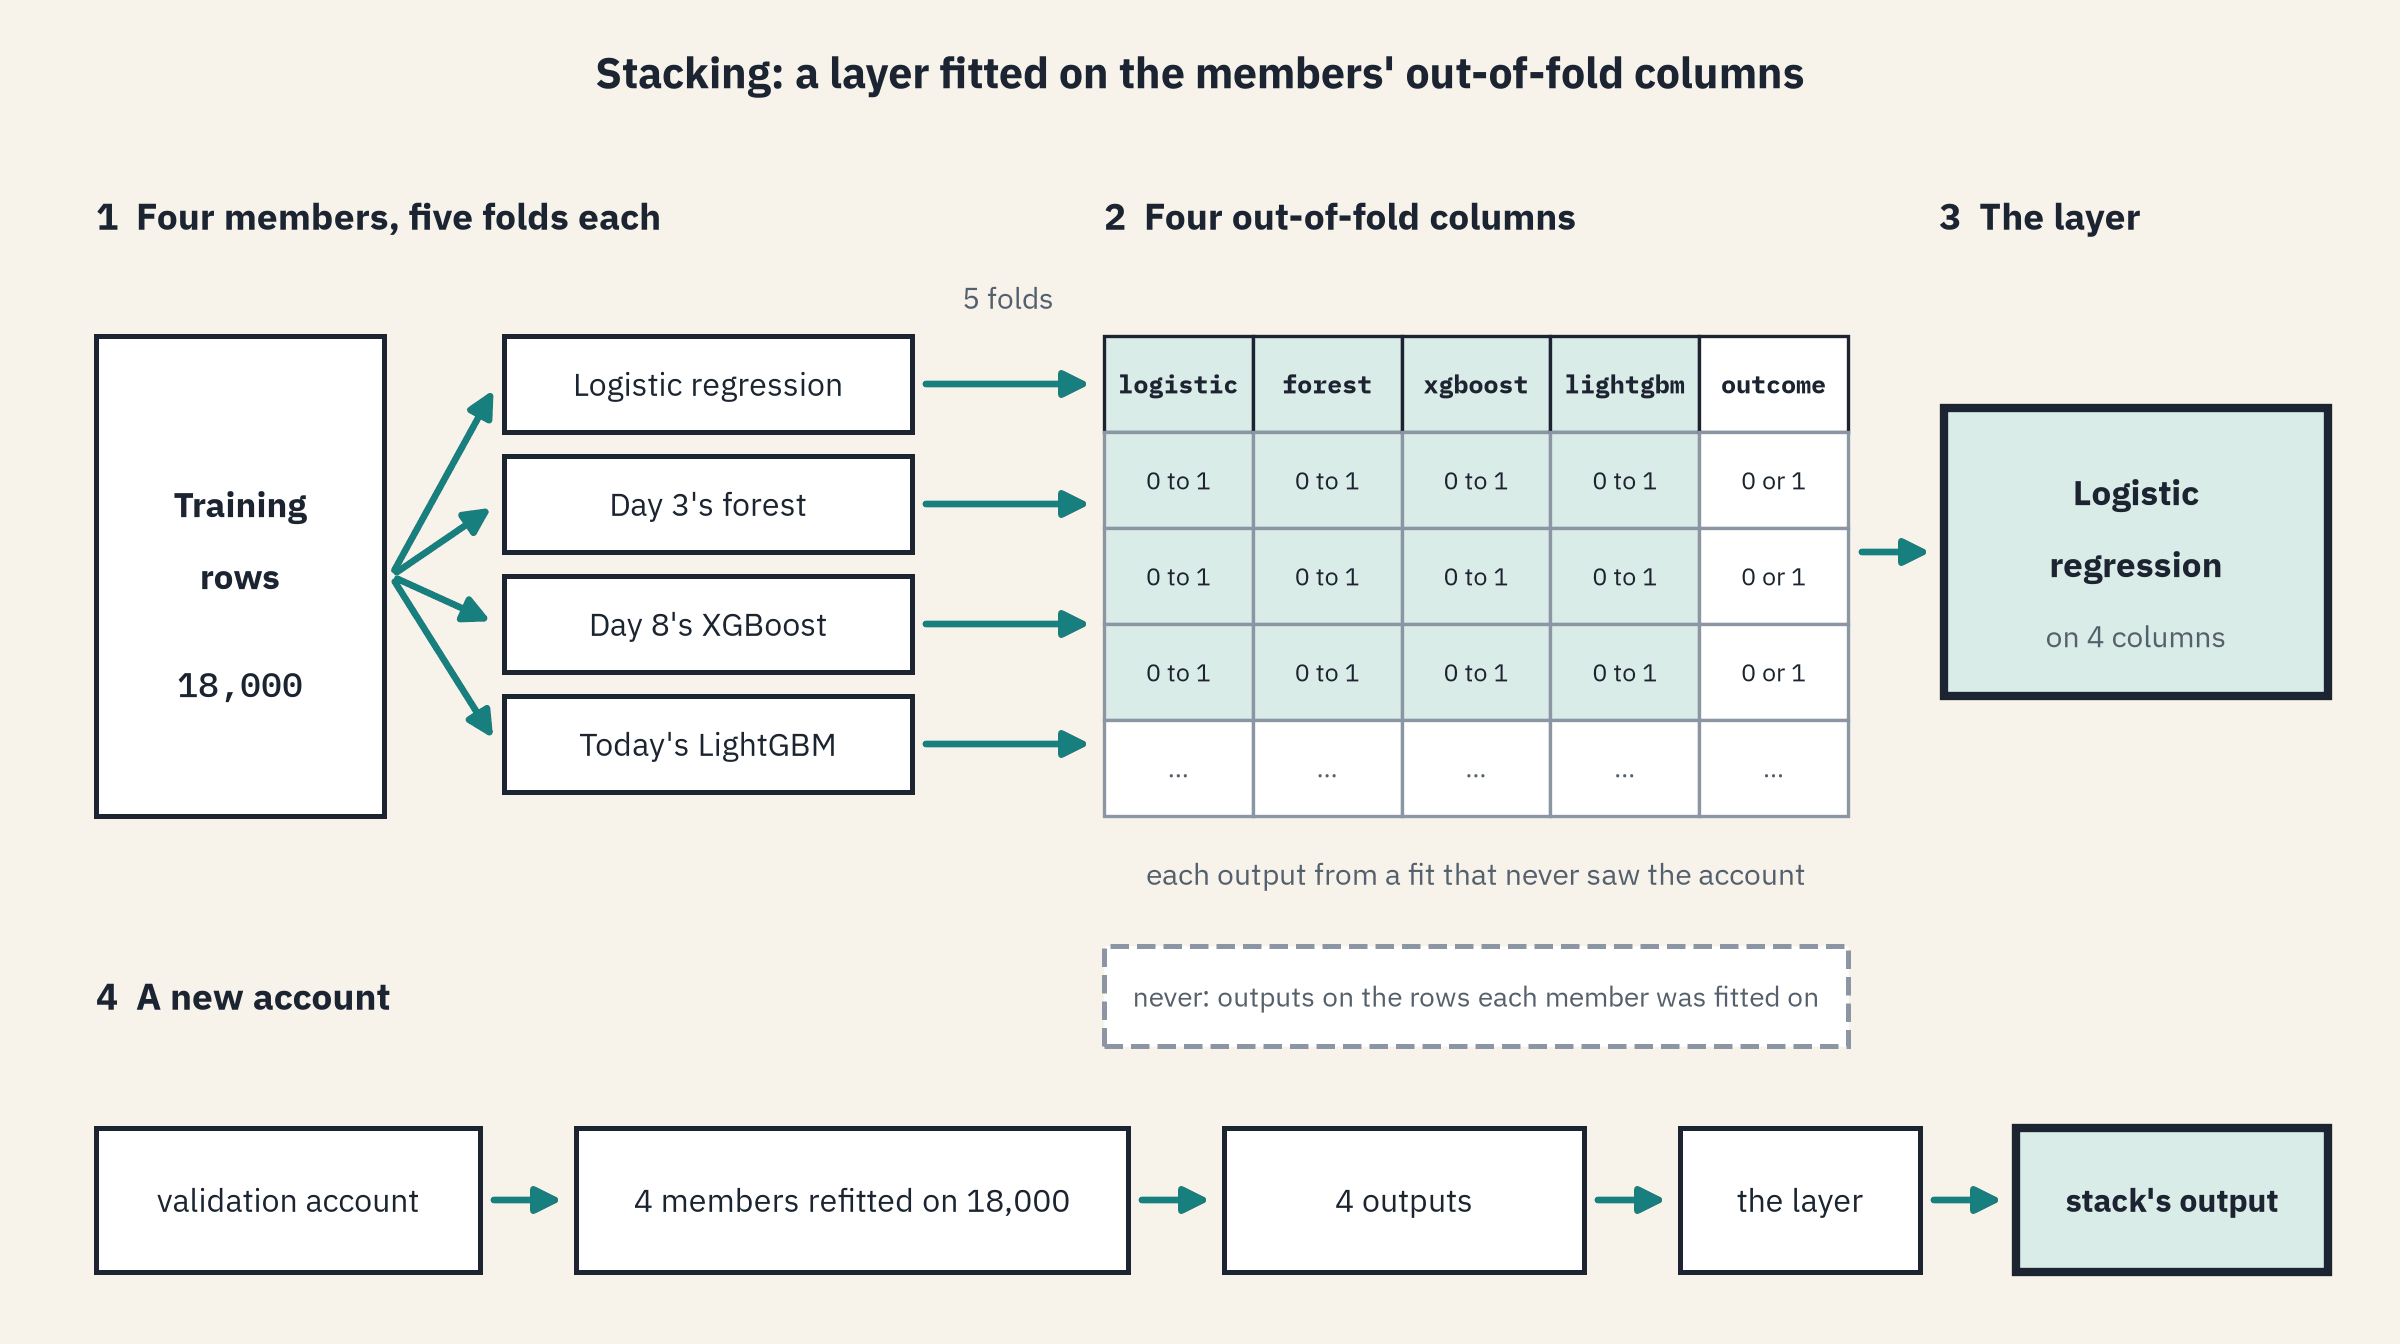)

**Stacking** fits a model on other models' outputs: the models below are the **members**, the model on top the **layer** (scikit-learn's final estimator).
The layer learns from each member's **out-of-fold** output, Course 4's capstone's term: one column per member, every account scored by a fit that never saw it.

## Four Columns

In [34]:
# each member's out-of-fold output for every training account: five fits, each scoring the fold it never saw
oof = pd.DataFrame({name: cross_val_predict(model, X_train, y_train, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
                    for name, model in models.items()}, index=X_train.index)
print({name: round(roc_auc_score(y_train, oof[name]), 4) for name in oof})
oof.head(3)

{'logistic': 0.7273, 'forest': 0.7832, 'xgboost': 0.7839, 'lightgbm': 0.7822}


,logistic,forest,xgboost,lightgbm
10574,0.2195,0.1897,0.1947,0.1794
11330,0.0855,0.1040,0.0912,0.0873
7127,0.0154,0.0286,0.0461,0.0470


Out of fold, the three tree models score 0.7822 to 0.7839 on the training rows, about what they score on the validation rows.

## Why Out of Fold

In [35]:
# each member's output on the very accounts it was fitted on
in_sample = pd.DataFrame({name: model.predict_proba(X_train)[:, 1] for name, model in models.items()}, index=X_train.index)
print({name: round(roc_auc_score(y_train, in_sample[name]), 4) for name in in_sample})

{'logistic': 0.7296, 'forest': 0.8204, 'xgboost': 0.81, 'lightgbm': 0.8355}


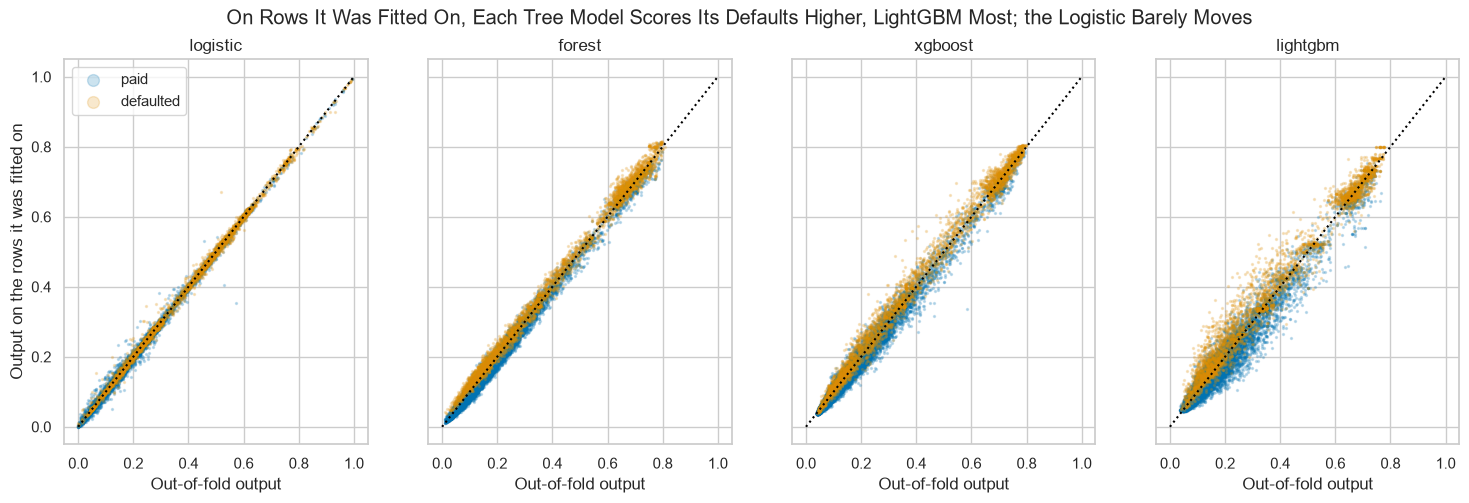

In [36]:
# small multiples: each member's out-of-fold output across, its output on its own fitted rows up, defaults in orange
fig, axes = plt.subplots(1, 4, figsize=(18, 5), sharex=True, sharey=True)
for ax, name in zip(axes, models):
    ax.scatter(oof.loc[y_train == 0, name], in_sample.loc[y_train == 0, name], s=2, alpha=0.2, label="paid")
    ax.scatter(oof.loc[y_train == 1, name], in_sample.loc[y_train == 1, name], s=2, alpha=0.2, label="defaulted")
    ax.plot([0, 1], [0, 1], color="black", linestyle=":")
    ax.set(title=name, xlabel="Out-of-fold output")
axes[0].set_ylabel("Output on the rows it was fitted on")
axes[0].legend(loc="upper left", markerscale=6)
fig.suptitle("On Rows It Was Fitted On, Each Tree Model Scores Its Defaults Higher, LightGBM Most; the Logistic Barely Moves")
plt.show()

On rows a tree model was fitted on, its defaulted accounts score higher than out of fold, most for LightGBM, 0.8355 in sample; the logistic regression barely moves, 0.7296 against 0.7273.

A layer fitted on those numbers would trust whichever member memorised most; Exercise 4 tests it.

## Where the Members Disagree

In [37]:
# how alike the four columns are
oof.corr()

,logistic,forest,xgboost,lightgbm
logistic,1.0000,0.8570,0.8508,0.8512
forest,0.8570,1.0000,0.9816,0.9833
xgboost,0.8508,0.9816,1.0000,0.9832
lightgbm,0.8512,0.9833,0.9832,1.0000


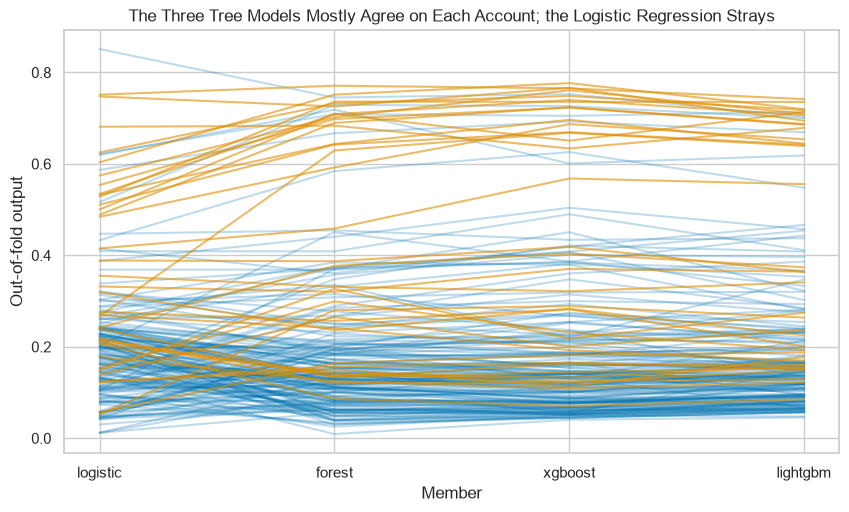

In [38]:
# 200 training accounts as lines across the four out-of-fold columns: paid in blue, defaulted in orange
lines = oof.sample(200, random_state=SEED)
outcome = y_train.loc[lines.index]
fig, ax = plt.subplots(figsize=(10, 5.5))
ax.plot(range(4), lines[outcome == 0].T, color="C0", alpha=0.25)
ax.plot(range(4), lines[outcome == 1].T, color="C1", alpha=0.6)
ax.set(xticks=range(4), xticklabels=list(oof.columns), xlabel="Member", ylabel="Out-of-fold output")
ax.set_title("The Three Tree Models Mostly Agree on Each Account; the Logistic Regression Strays")
plt.show()

The three tree models correlate at 0.98 with one another, the logistic regression at about 0.85.

So most lines run flat across the three tree columns and bend at the logistic one.

## The Layer

In [39]:
# a logistic regression fitted on the four out-of-fold columns
layer = LogisticRegression().fit(oof, y_train)
print("Coefficients:", dict(zip(oof.columns, layer.coef_[0].round(4).tolist())), " Intercept:", round(layer.intercept_[0], 4))

Coefficients: {'logistic': -0.6874, 'forest': 1.9285, 'xgboost': 2.2783, 'lightgbm': 1.7874}  Intercept: -2.6485


### Interpretation of the Coefficients

The four columns share one 0 to 1 scale, so the coefficients compare directly.

The layer leans on XGBoost most, 2.2783, then the forest and LightGBM, and puts a negative weight on Course 4's logistic regression.

A negative weight on a column that tracks the others is a correction among the columns, not a statement about any account.

## StackingClassifier Does the Same

`StackingClassifier` does all of it in one object: the out-of-fold columns from `cv=folds`, the layer, and every member refitted on all the training rows.
`stack_method="predict_proba"` hands the layer each member's output.

In [40]:
# the four members, a logistic layer, the same folds
stack = StackingClassifier(list(models.items()), final_estimator=LogisticRegression(), stack_method="predict_proba", cv=folds, n_jobs=1)
stack.fit(X_train, y_train)
print("Largest gap between the two layers' coefficients:", np.abs(stack.final_estimator_.coef_[0] - layer.coef_[0]).max())

Largest gap between the two layers' coefficients: 0.0


In [41]:
# the members' validation outputs as four columns, through the hand layer, against the stack's own
valid_columns = pd.DataFrame({name: model.predict_proba(X_valid)[:, 1] for name, model in models.items()}, index=X_valid.index)
print("The same validation outputs:", np.allclose(layer.predict_proba(valid_columns)[:, 1], stack.predict_proba(X_valid)[:, 1]))

The same validation outputs: True


**The stack is the four columns, a logistic layer and four refits, in one object.**

# Does the Stack Beat Its Best Member?

A **blend** weights the members' outputs by numbers we choose; the plain average gives each the same weight.

**Predict 4**

Q. The best member, Day 3's chosen forest, scores 0.7844 on the validation rows. What will the stack score? Write down a number.

## Scoring the Stack

In [42]:
# the stack on the validation rows, beside two plain averages of the members
stack_out = stack.predict_proba(X_valid)[:, 1]
print("Stack: ROC AUC", round(roc_auc_score(y_valid, stack_out), 4), " AP", round(average_precision_score(y_valid, stack_out), 4))
print("Average of all four:", round(roc_auc_score(y_valid, valid_columns.mean(axis=1)), 4),
      " of the three tree models:", round(roc_auc_score(y_valid, valid_columns[["forest", "xgboost", "lightgbm"]].mean(axis=1)), 4))
print("The forest's AP:", round(average_precision_score(y_valid, valid_columns["forest"]), 4))

Stack: ROC AUC 0.7846  AP 0.5575
Average of all four: 0.7791  of the three tree models: 0.7842
The forest's AP: 0.5562


## Every Blend of Three

Three weights that add to 1 make a point in a triangle: each corner is one member alone, the middle the plain average.

In [43]:
# every blend of the three tree models' out-of-fold columns in steps of 0.05, scored on the training outcome
trio = oof[["forest", "xgboost", "lightgbm"]]
blends = []
for a in range(21):
    for b in range(21 - a):
        weights = np.array([a, b, 20 - a - b]) / 20
        blends.append(list(weights) + [roc_auc_score(y_train, (trio * weights).sum(axis=1))])
blends = pd.DataFrame(blends, columns=["forest", "xgboost", "lightgbm", "ROC AUC"])
best = blends.loc[blends["ROC AUC"].idxmax()]
print(len(blends), "blends. Best:", best.round(4).to_dict(), " Within 0.001 of it:", (blends["ROC AUC"] >= best["ROC AUC"] - 0.001).sum())

231 blends. Best: {'forest': 0.3, 'xgboost': 0.5, 'lightgbm': 0.2, 'ROC AUC': 0.7849}  Within 0.001 of it: 183


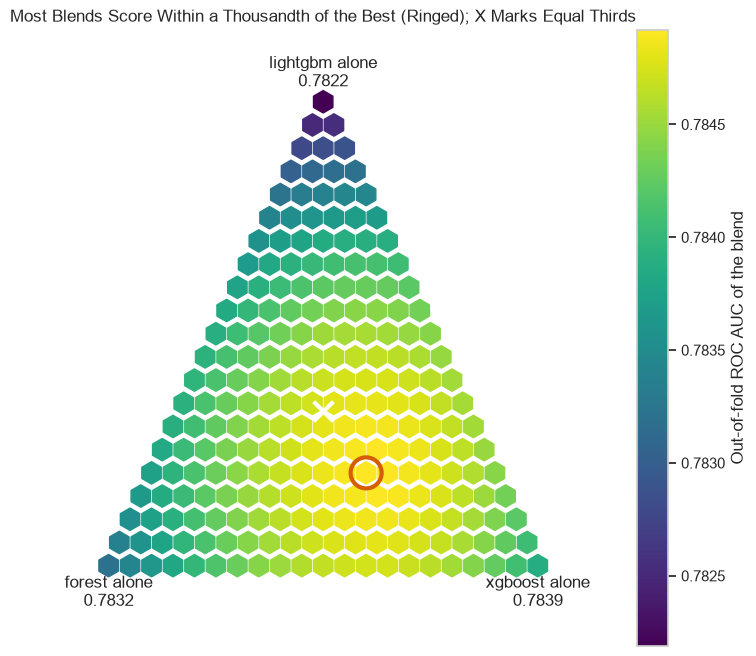

In [44]:
# a ternary heatmap: XGBoost at the bottom right, LightGBM at the top, the forest at the bottom left
across, up = blends["xgboost"] + blends["lightgbm"] / 2, blends["lightgbm"] * np.sqrt(3) / 2
fig, ax = plt.subplots(figsize=(9, 8))
dots = ax.scatter(across, up, c=blends["ROC AUC"], cmap="viridis", s=260, marker="h")
fig.colorbar(dots, label="Out-of-fold ROC AUC of the blend")
for x, yy, name in [(0, -0.05, "forest"), (1, -0.05, "xgboost"), (0.5, 0.92, "lightgbm")]:
    ax.text(x, yy, f"{name} alone\n{roc_auc_score(y_train, oof[name]):.4f}", ha="center", va="center")
ax.scatter(best["xgboost"] + best["lightgbm"] / 2, best["lightgbm"] * np.sqrt(3) / 2, s=500, facecolor="none", edgecolor="C3", linewidth=3)
ax.scatter(0.5, np.sqrt(3) / 6, s=200, marker="x", color="white", linewidth=3)
ax.set(xlim=(-0.15, 1.15), ylim=(-0.15, 1.0))
ax.set_axis_off()
ax.set_title("Most Blends Score Within a Thousandth of the Best (Ringed); X Marks Equal Thirds")
plt.show()

In [45]:
# the best blend and the equal thirds, on the validation rows
valid_trio = valid_columns[["forest", "xgboost", "lightgbm"]]
print("Best blend:", round(roc_auc_score(y_valid, (valid_trio * best[["forest", "xgboost", "lightgbm"]].values).sum(axis=1)), 4),
      " Equal thirds:", round(roc_auc_score(y_valid, valid_trio.mean(axis=1)), 4))

Best blend: 0.7842  Equal thirds: 0.7842


The triangle is nearly flat: 183 of the 231 blends score within 0.001 of the best, and on the validation rows the best blend and equal thirds tie at 0.7842.

## The Board

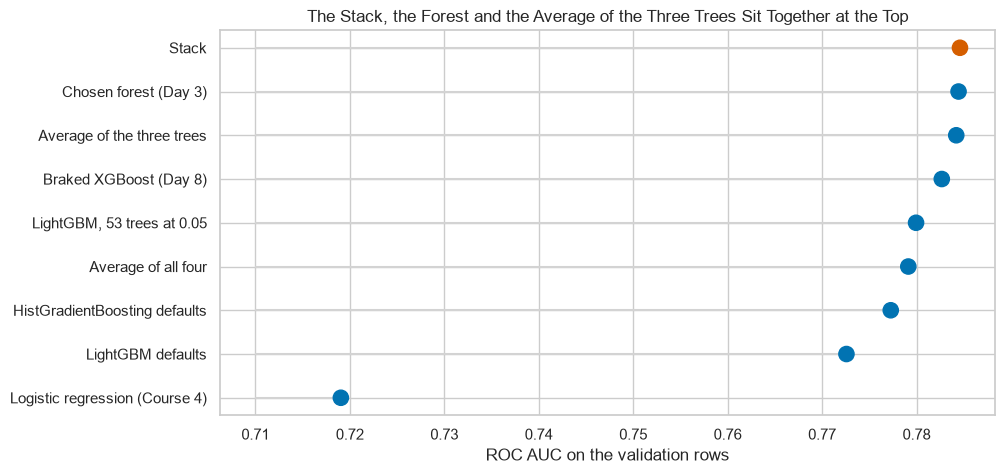

In [46]:
# validation ROC AUC of every model and combination today, sorted, the stack highlighted
scores = comparison["validation"].copy()
scores["Average of all four"] = roc_auc_score(y_valid, valid_columns.mean(axis=1))
scores["Average of the three trees"] = roc_auc_score(y_valid, valid_trio.mean(axis=1))
scores["Stack"] = roc_auc_score(y_valid, stack_out)
scores = scores.sort_values()
plt.hlines(scores.index, 0.71, scores, color="lightgray")
plt.scatter(scores, scores.index, s=120, color=["C3" if name == "Stack" else "C0" for name in scores.index], zorder=3)
plt.xlabel("ROC AUC on the validation rows")
plt.title("The Stack, the Forest and the Average of the Three Trees Sit Together at the Top")
plt.show()

### Interpretation of the Stack

The stack scores 0.7846 against the forest's 0.7844, and 0.5575 against 0.5562 in average precision.

The plain average of the three tree models scores 0.7842; the average of all four, logistic included, 0.7791.

Here the layer's real work was keeping the weak member down; on members this alike, there is little left to combine.

**Stacking adds next to nothing here, where the tree members correlate at 0.98; whether a gap of 0.0002 is more than noise is Day 10's question.**

# Insights and Conclusion

LightGBM's defaults scored 0.7726 on the validation rows, with a smaller training gap than XGBoost's defaults.

Leaf-wise trees of 31 leaves reached 7 to 20 questions deep, and bins turned 14,404 bill amounts into at most 142 thresholds.

On five folds, fewer leaves, the largest leaves and a smaller step held out best; the stopping rows kept 53 trees at 0.05.

Split counts and gain rank `PAY_0` 14th and 1st: what the model leans on depends on `importance_type`.

Out-of-fold columns make a stack honest; the stack and a plain average of the trees both land near the forest.

No output here is a decision about an account.

**Day 10 puts an interval on every gap before naming a winner.**

# Wrapping Up

## You Can Now

By the end of this notebook, you can:

* Fit `LGBMClassifier` on one thread and read its trees with `.trees_to_dataframe()`.
* Draw a tree as an icicle chart, and count the thresholds binned columns allow.
* Score settings on five folds and stop LightGBM's trees on stopping rows with a callback.
* Read LightGBM's split-count and gain importances and name which one you quote.
* Build out-of-fold columns, fit a stacking layer on them, and check `StackingClassifier` against it.

## Exercises

Run this cell first: `check()` marks each answer as correct, not yet, or not attempted.

In [47]:
# check() compares your answer with the expected one
def check(label, answer, expected):
    if answer is ...:
        print(label + ": not attempted yet")
    elif isinstance(expected, float) and abs(answer - expected) < 1e-6:
        print(label + ": correct")
    elif answer == expected:
        print(label + ": correct")
    else:
        print(label + ": not yet. You have", answer)

### Exercise 1

**Weighting the Defaults in LightGBM**

Q. Fit today's LightGBM, 53 trees at 0.05, on the training rows with `scale_pos_weight` set to the paid accounts over the defaulted ones, as Day 8 did. Store its validation ROC AUC in `ex1_auc` and its average output on the validation rows in `ex1_mean`.

In [48]:
# paid accounts over defaulted accounts, as Day 8 set the weight
weight = (y_train == 0).sum() / (y_train == 1).sum()
weighted = LGBMClassifier(n_estimators=53, learning_rate=0.05, scale_pos_weight=weight, random_state=SEED, n_jobs=1,
                          verbose=-1).fit(X_train, y_train)
ex1_auc = roc_auc_score(y_valid, weighted.predict_proba(X_valid)[:, 1])
ex1_mean = weighted.predict_proba(X_valid)[:, 1].mean()
print("Validation ROC AUC:", round(ex1_auc, 4), " Average output:", round(ex1_mean, 4))

Validation ROC AUC: 0.777  Average output: 0.4033


In [49]:
check("Exercise 1 the validation ROC AUC", ex1_auc, 0.7770448040346578)
check("Exercise 1 the average output", ex1_mean, 0.40329404967843113)

Exercise 1 the validation ROC AUC: correct
Exercise 1 the average output: correct


### Exercise 2

**A Stack of Two**

Q. Fit a logistic layer on the forest's and LightGBM's out-of-fold columns only, and store its validation ROC AUC, on those two members' validation columns, in `ex2_auc`.

In [50]:
# a logistic layer on two out-of-fold columns, scored on the same two members' validation columns
two = LogisticRegression().fit(oof[["forest", "lightgbm"]], y_train)
ex2_auc = roc_auc_score(y_valid, two.predict_proba(valid_columns[["forest", "lightgbm"]])[:, 1])
print("Coefficients:", two.coef_[0].round(4).tolist(), " Validation ROC AUC:", round(ex2_auc, 4))

Coefficients: [2.8147, 2.7456]  Validation ROC AUC: 0.7839


In [51]:
check("Exercise 2 the validation ROC AUC", ex2_auc, 0.7839349041480093)

Exercise 2 the validation ROC AUC: correct


### Exercise 3

**A Function for a Blend**

Q. Write `blend(a, b, weight)` that returns `weight * a + (1 - weight) * b`. Try XGBoost's weight at 0, 0.05, ..., 1 against LightGBM on the out-of-fold columns, store the weight with the highest ROC AUC in `ex3_weight`, and that blend's validation ROC AUC in `ex3_auc`.

In [52]:
# a weighted blend of two outputs
def blend(a, b, weight):
    return weight * a + (1 - weight) * b

# XGBoost's weight chosen on the out-of-fold columns, then the blend scored once on the validation rows
weights = [w / 20 for w in range(21)]
fold_scores = [roc_auc_score(y_train, blend(oof["xgboost"], oof["lightgbm"], w)) for w in weights]
ex3_weight = weights[int(np.argmax(fold_scores))]
ex3_auc = roc_auc_score(y_valid, blend(valid_columns["xgboost"], valid_columns["lightgbm"], ex3_weight))
print("Weight:", ex3_weight, " Validation ROC AUC:", round(ex3_auc, 4))

Weight: 0.65  Validation ROC AUC: 0.7829


In [53]:
check("Exercise 3 the weight", ex3_weight, 0.65)
check("Exercise 3 the validation ROC AUC", ex3_auc, 0.7828590416074901)

Exercise 3 the weight: correct
Exercise 3 the validation ROC AUC: correct


### Exercise 4: AI check

**The Stack That Saw Its Own Answers**

You asked an AI assistant for a function that builds a stacking layer's columns.
This came back.
It runs, and the layer it feeds looks confident.
Test it, then find the one bug.

In [54]:
# written for this course in the style of an AI assistant's answer: it runs, and it has one bug
def stack_columns(models, X, y):
    # one column per model: each model's output for every row, for a stacking layer to learn from
    columns = {}
    for name, model in models.items():
        model.fit(X, y)
        columns[name] = model.predict_proba(X)[:, 1]
    return pd.DataFrame(columns, index=X.index)

ai_columns = stack_columns(models, X_train, y_train)
ai_layer = LogisticRegression().fit(ai_columns, y_train)
print("Coefficients:", dict(zip(ai_columns.columns, ai_layer.coef_[0].round(4).tolist())))
print("Validation ROC AUC:", round(roc_auc_score(y_valid, ai_layer.predict_proba(valid_columns)[:, 1]), 4))

Coefficients: {'logistic': -2.5188, 'forest': -1.0139, 'xgboost': -1.2931, 'lightgbm': 10.6573}
Validation ROC AUC: 0.7722


In [55]:
# the test: a stacking column must hold each account's output from a fit that never saw it, as the out-of-fold columns do
assert np.allclose(ai_columns, oof), "the columns are outputs on the rows each model was fitted on, not out-of-fold outputs"

AssertionError: the columns are outputs on the rows each model was fitted on, not out-of-fold outputs

Q. Fix the function and run it on the two quick members, the logistic regression and LightGBM, so the test passes on their two columns. Fit a logistic layer on those two columns and store its coefficient on LightGBM, through `float(...)`, in `ex4_lightgbm`.

In [56]:
# the fix: each column from cross_val_predict, so every row's output comes from a fit that never saw it
def stack_columns(models, X, y):
    columns = {}
    for name, model in models.items():
        columns[name] = cross_val_predict(model, X, y, cv=folds, method="predict_proba", n_jobs=1)[:, 1]
    return pd.DataFrame(columns, index=X.index)

# the two quick members: their fixed columns match today's out-of-fold columns
quick = stack_columns({"logistic": models["logistic"], "lightgbm": models["lightgbm"]}, X_train, y_train)
print("The same as the out-of-fold columns:", np.allclose(quick, oof[["logistic", "lightgbm"]]))

# a logistic layer on the two fixed columns
quick_layer = LogisticRegression().fit(quick, y_train)
ex4_lightgbm = float(quick_layer.coef_[0][1])
print("Coefficients:", quick_layer.coef_[0].round(4).tolist(), " LightGBM:", ex4_lightgbm)

The same as the out-of-fold columns: True
Coefficients: [-0.0501, 5.5698]  LightGBM: 5.569791070380708


In [57]:
check("Exercise 4 LightGBM's coefficient", ex4_lightgbm, 5.569791070380708)

Exercise 4 LightGBM's coefficient: correct


## Congratulations!

You grew LightGBM's trees leaf by leaf and watched them run deep where the accounts are.
You counted the thresholds its bins allow, stopped its trees on rows of your own, and read two importances that disagree.
You built a stack by hand from out-of-fold columns and caught the version that grades members on their own answers.
In Day 10 you put intervals on today's gaps before naming any winner.

[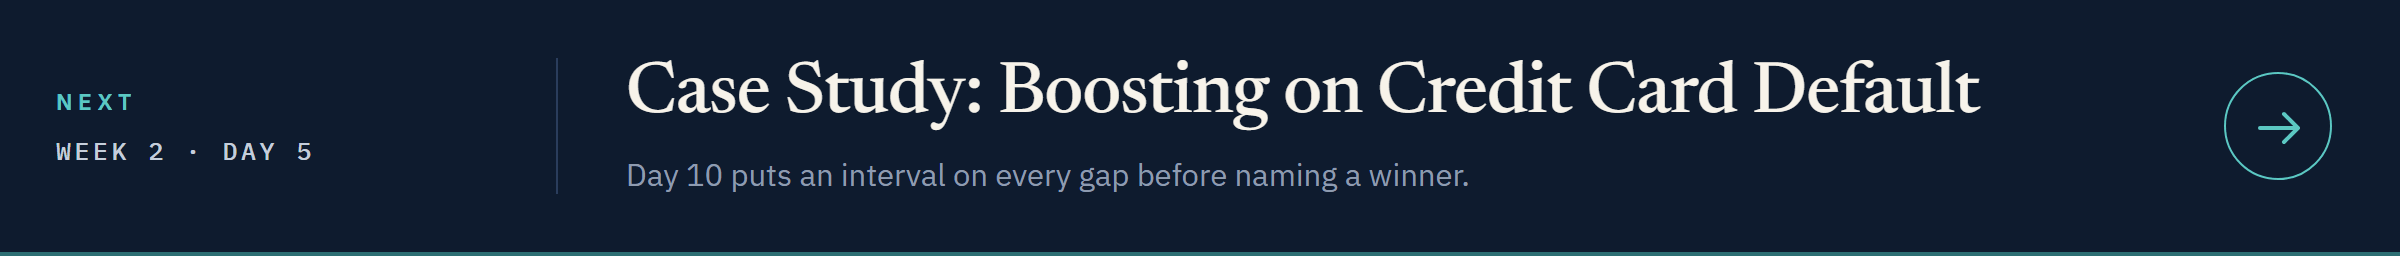](../day5/10_case_study_boosting_on_credit_card_default.ipynb)

[Open Day 5 in Colab](https://colab.research.google.com/github/lenamonj/python-fixed-income/blob/main/course05_advanced_ml/week2/day5/10_case_study_boosting_on_credit_card_default.ipynb)